# Práctica: Gasto en Salud como % del PIB

**Materia:** Tópicos de Big Data
**Fuente:** Our World in Data (OWID), indicador *Total healthcare spending as a share of GDP*

**Objetivo:** extraer, limpiar y explorar la serie histórica del gasto total en salud
como porcentaje del PIB a nivel mundial, con foco en México y comparación con
otros países.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

OPCIONES_OWID = {"User-Agent": "Our World In Data data fetch/1.0"}

## 1. Extracción del dataset

In [2]:
url_salud = (
    "https://ourworldindata.org/grapher/total-healthcare-expenditure-gdp.csv"
    "?v=1&csvType=full&useColumnShortNames=true"
)

gasto_salud = pd.read_csv(url_salud, storage_options=OPCIONES_OWID)
gasto_salud.shape

(4756, 4)

## 2. Exploración inicial

In [3]:
gasto_salud.head()

,entity,code,year,current_health_expenditure__che__as_percentage_of_gross_domestic_product__gdp__pct
0,Afghanistan,AFG,2002,9.443391
1,Afghanistan,AFG,2003,8.941258
2,Afghanistan,AFG,2004,9.808474
3,Afghanistan,AFG,2005,9.948289
4,Afghanistan,AFG,2006,10.622766


In [4]:
gasto_salud.columns.tolist()

['entity',
 'code',
 'year',
 'current_health_expenditure__che__as_percentage_of_gross_domestic_product__gdp__pct']

In [5]:
gasto_salud.dtypes

entity                                                                                    str
code                                                                                      str
year                                                                                    int64
current_health_expenditure__che__as_percentage_of_gross_domestic_product__gdp__pct    float64
dtype: object

In [6]:
gasto_salud.isnull().sum()

entity                                                                                0
code                                                                                  0
year                                                                                  0
current_health_expenditure__che__as_percentage_of_gross_domestic_product__gdp__pct    0
dtype: int64

## 3. Renombrar columnas a nombres manejables

In [7]:
col_gasto = [c for c in gasto_salud.columns if "health_expenditure" in c][0]

gasto_salud = gasto_salud.rename(columns={
    "entity": "pais",
    "code": "codigo",
    "year": "anio",
    col_gasto: "gasto_salud_pct_pib",
})

gasto_salud.head(3)

,pais,codigo,anio,gasto_salud_pct_pib
0,Afghanistan,AFG,2002,9.443391
1,Afghanistan,AFG,2003,8.941258
2,Afghanistan,AFG,2004,9.808474


## 4. México: evolución del gasto en salud

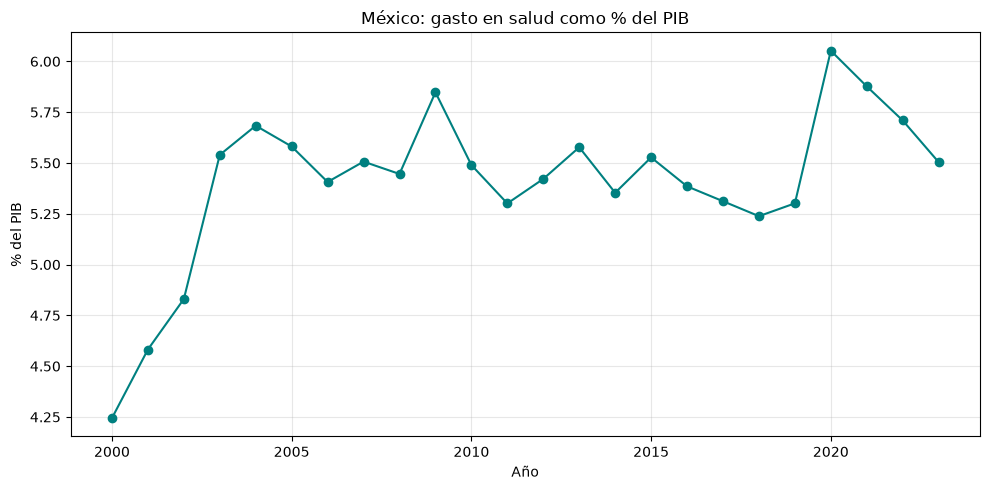

In [8]:
mexico = gasto_salud[gasto_salud["pais"] == "Mexico"].sort_values("anio")

plt.figure(figsize=(10, 5))
plt.plot(mexico["anio"], mexico["gasto_salud_pct_pib"], marker="o", color="teal")
plt.title("México: gasto en salud como % del PIB")
plt.xlabel("Año")
plt.ylabel("% del PIB")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 5. Comparación internacional

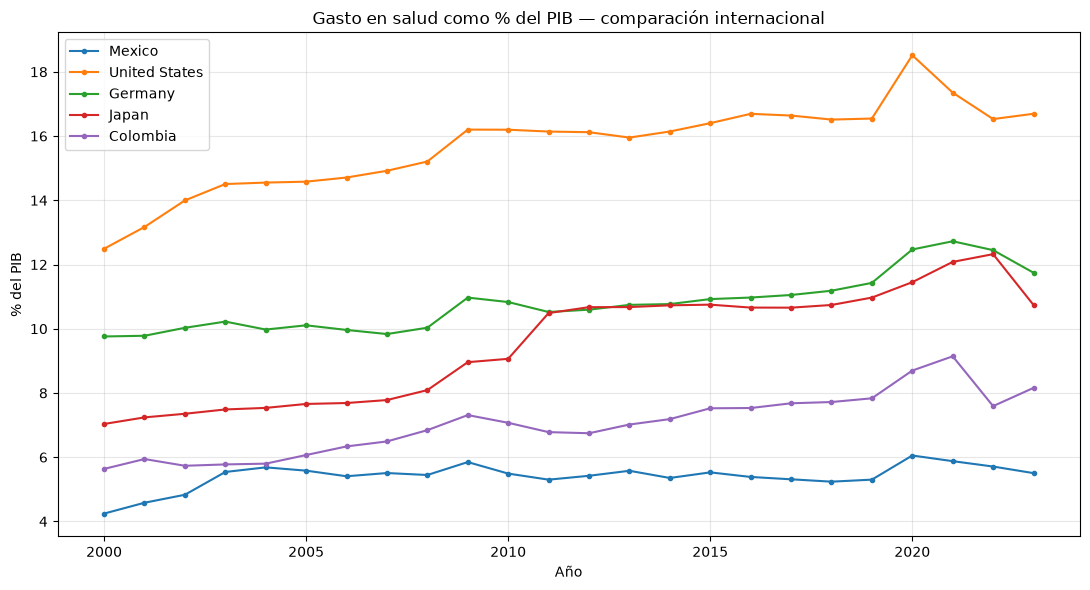

In [9]:
paises = ["Mexico", "United States", "Germany", "Japan", "Colombia"]
comparacion = gasto_salud[gasto_salud["pais"].isin(paises)]

plt.figure(figsize=(11, 6))
for pais in paises:
    datos_pais = comparacion[comparacion["pais"] == pais]
    plt.plot(datos_pais["anio"], datos_pais["gasto_salud_pct_pib"], marker=".", label=pais)

plt.title("Gasto en salud como % del PIB — comparación internacional")
plt.xlabel("Año")
plt.ylabel("% del PIB")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 6. Top 10 países con mayor gasto en salud (2021)

In [10]:
top_2021 = (
    gasto_salud[(gasto_salud["anio"] == 2021) & (gasto_salud["codigo"].notna())]
    .sort_values("gasto_salud_pct_pib", ascending=False)
    .head(10)
)
top_2021[["pais", "codigo", "gasto_salud_pct_pib"]]

,pais,codigo,gasto_salud_pct_pib
19,Afghanistan,AFG,21.508444
4423,Tuvalu,TUV,18.574112
4541,United States,USA,17.352077
3157,Niue,NIU,15.082194
3277,Palau,PLW,14.552760
1099,Cuba,CUB,13.787466
2437,Liberia,LBR,13.271760
1696,Germany,DEU,12.724033
2688,Marshall Islands,MHL,12.492571
787,Canada,CAN,12.381066
